<a href="https://colab.research.google.com/github/mahendranvaishakh41-hue/wing-spar-stress-analysis/blob/main/Wing_Spar_Load_and_Stress_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wing Spar Load and Stress Analysis for a Light Aircraft

This notebook estimates the loads on a light aircraft's wing and checks whether the main spar is strong enough at the design load factor (n = 3.8).

**Method:** Schrenk lift distribution → shear force → bending moment → spar root stress (σ = My/I) → margins of safety. Results are verified against hand calculations.

**Author:** Vaishakh Mahendran | November 2026

In [17]:
# Libraries
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True)

## 1. Inputs

All aircraft, spar and material values are stored here, so the whole analysis can be rerun for a different design by changing one cell.

In [18]:
# Inputs
aircraft = {
    "mass": 1100,          # kg
    "wing_area": 16,       # m^2
    "span": 10,            # m
    "root_chord": 2.0,     # m
    "tip_chord": 1.2,      # m
    "load_factor": 3.8,    # limit load factor (FAR 23.337)
}
spar = {
    "h": 0.20,             # spar height (m)
    "b": 0.08,             # flange width (m)
    "tf": 0.012,           # flange thickness (m)
    "tw": 0.004,           # web thickness (m)
}
material = {
    "yield_strength": 345e6,      # Pa (2024-T3, typical)
    "ultimate_strength": 483e6,   # Pa (2024-T3, typical)
    "safety_factor": 1.5,         # FAR 23.303
}

## 2. Aircraft loads

Aircraft weight, wing loading, and the lift the wing must carry at different load factors (n = lift ÷ weight).

In [19]:
# Weight and wing loading
def calculate_weight(mass):
  return mass*9.81
weight = calculate_weight(aircraft["mass"])
print("Weight:", round(weight,2), "N")
def calculate_wing_loading(weight,area):
  return weight/area
loading = calculate_wing_loading(weight, aircraft["wing_area"])
print ("wing loading:", round(loading,2), "N/m^2")


Weight: 10791.0 N
wing loading: 674.44 N/m^2


In [20]:
# Lift at different load factors
def calculate_lift(weight, n):
    return n * weight

lifts = []
for n in [1, 1.5, 2, 3.8]:
    lift = calculate_lift(weight, n)
    lifts.append(lift)
print(lifts)

[10791.0, 16186.5, 21582.0, 41005.799999999996]


## 3. Wing geometry and Schrenk lift distribution

The tapered wing is described at 51 points from root to tip. Schrenk's method estimates the spanwise lift as the average of the wing's real chord shape and an ideal ellipse of the same area.

In [21]:
#wing geometry
span = aircraft["span"]
root_chord = aircraft["root_chord"]
tip_chord = aircraft["tip_chord"]
half_span = span/2
y = np.linspace(0, half_span, 51)   #position along one wing, root to tip
print("Points along half-span:", len(y))
chord = root_chord - (root_chord-tip_chord)*y/half_span
print("Chord at root / tip:", chord[0], "/", chord[-1], "m")

Points along half-span: 51
Chord at root / tip: 2.0 / 1.2 m


In [22]:
#schrenk lift distribution
# Method: Schrenk (1940), NACA TM 948
wing_area = aircraft["wing_area"]
ellipse_chord = (4*wing_area/(np.pi*span))*np.sqrt(1-(y/half_span)**2)
schrenk_chord = (chord+ellipse_chord)/2
print("Schrenk chord at root / tip:", round(schrenk_chord[0], 2), "/", round(schrenk_chord[-1], 2), "m")

Schrenk chord at root / tip: 2.02 / 0.6 m


In [23]:
# Lift per metre along the wing
# Limit load factor n = 3.8 (FAR 23.337, normal category)
n = aircraft["load_factor"]
lift_per_metre = n*loading*schrenk_chord
print("Lift per metre at root / tip:", round(lift_per_metre[0]), "/", round(lift_per_metre[-1]), "N/m")

Lift per metre at root / tip: 5173 / 1538 N/m


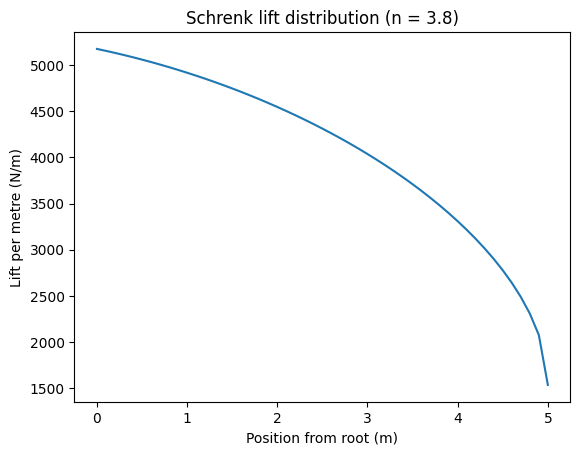

In [24]:
# Graph: Lift Distribution
plt.plot(y,lift_per_metre)
plt.xlabel("Position from root (m)")
plt.ylabel("Lift per metre (N/m)")
plt.title("Schrenk lift distribution (n = 3.8)")
plt.show()

## 4. Shear force

The shear force at each point is the total lift on the wing beyond that point (the area under the lift curve from that point to the tip). It is zero at the tip and largest at the root.

In [25]:
# Shear force
# Shear = area under the lift curve from each point to the tip (Megson, Aircraft Structures)
total_lift = np.trapezoid(lift_per_metre, y)
print("Total lift on one wing:", round(total_lift, 1), "N")
shears = []
for i in range(len(y)):
  shear = np.trapezoid(lift_per_metre[i:], y[i:])
  shears.append(shear)
shears = np.array(shears)
print("Shear force at root:", round(shears[0]), "N")

Total lift on one wing: 20492.1 N
Shear force at root: 20492 N


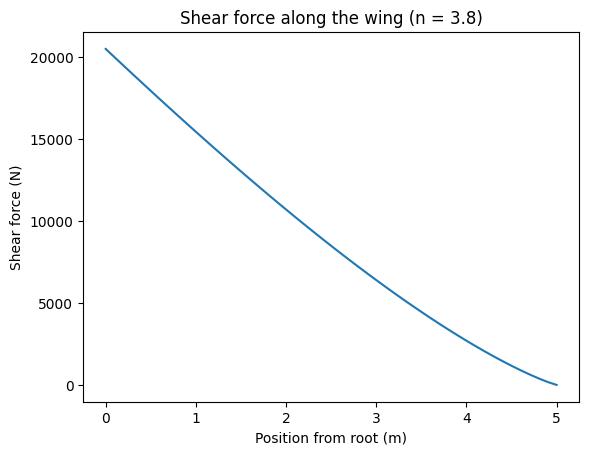

In [26]:
# Graph shear force
plt.plot(y,shears)
plt.xlabel("Position from root (m)")
plt.ylabel("Shear force (N)")
plt.title("Shear force along the wing (n = 3.8)")
plt.show()

## 5. Bending moment

The bending moment at each point is the area under the shear force curve from that point to the tip. It is largest at the root.

In [27]:
# Bending Moment
# Moment = area under the shear curve from each point to the tip (Megson)
moments = []
for i in range(len(y)):
  moment = np.trapezoid(shears[i:], y[i:])
  moments.append(moment)
moments = np.array(moments)
print("Bending moment at root:", round(moments[0]), "N·m")


Bending moment at root: 45198 N·m


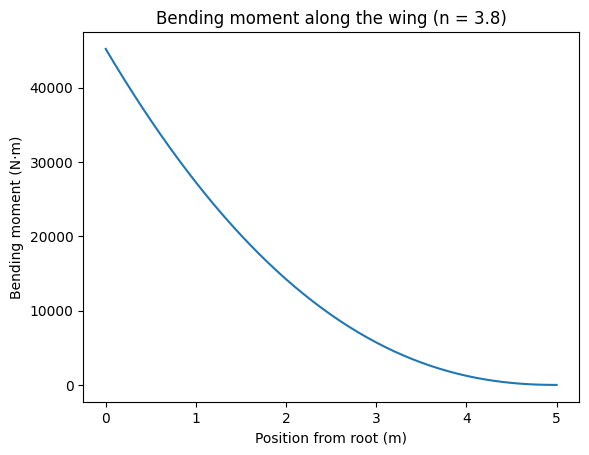

In [28]:
#Graph Bending moment
plt.plot(y,moments)
plt.xlabel("Position from root (m)")
plt.ylabel("Bending moment (N·m)")
plt.title("Bending moment along the wing (n = 3.8)")
plt.show()

## 6. Spar root bending stress

The spar is modelled as an aluminium I-beam. The bending stress at the root is found with σ = M × y / I.

In [29]:
# Spar root bending stress
# sigma = M*y/I (Megson, Aircraft Structures); I-beam spar
h = spar["h"]      # spar height (m)
b = spar["b"]      # flange width (m)
tf = spar["tf"]    # flange thickness (m)
tw = spar["tw"]    # web thickness (m)
I = (b * h**3 - (b - tw) * (h - 2*tf)**3) / 12
y_max = h / 2
M_root = moments[0]    # bending moment at the root
stress = M_root * y_max / I
print("I:", I, "m^4")
print("Stress:", round(stress / 1000000, 1), "MPa")

I: 1.8805418666666667e-05 m^4
Stress: 240.3 MPa


## 7. Margins of safety

The stress is compared with the strength of aluminium 2024-T3. At limit load the spar must not yield; at 1.5 × limit load (ultimate load) it must not break. A margin above 0 means safe.

In [30]:
# 2024-T3 typical strengths; safety factor 1.5 (FAR 23.303)
yield_strength = material["yield_strength"]
ultimate_strength = material["ultimate_strength"]
safety_factor = material["safety_factor"]
ultimate_stress = stress * safety_factor
MS_yield = yield_strength / stress - 1
MS_ultimate = ultimate_strength / ultimate_stress - 1
print("Margin of safety - Yield:", round(MS_yield, 2))
print("Margin of safety - Ultimate:", round(MS_ultimate, 2))

Margin of safety - Yield: 0.44
Margin of safety - Ultimate: 0.34


## 8. Verification against hand calculations

The Python results are checked against simple hand calculations: total lift = n × W / 2, and root bending moment = total lift × distance to the centre of lift.

In [31]:
# Verification: Python vs hand calculations
hand_lift = n * weight / 2
lift_diff = abs(hand_lift - total_lift) / hand_lift * 100
# 2.21 m = spanwise centre of Schrenk lift (average of trapezoid and ellipse centres)
hand_moment = hand_lift * 2.21
moment_diff = abs(hand_moment - moments[0]) / hand_moment * 100
print ("Lift difference:", round(lift_diff,2), "%")
print ("Moment Difference:", round(moment_diff,2), "%")

Lift difference: 0.05 %
Moment Difference: 0.25 %


## 9. Results summary

Key results for one wing at the design load factor.

In [32]:
# Results summary
print("Design load factor:", n)
print("Total lift on one wing:", round(total_lift), "N")
print("Root shear force:", round(shears[0]), "N")
print("Root bending moment:", round(moments[0]), "N·m")
print("Root bending stress:", round(stress / 1e6, 1), "MPa")
print("Margin of safety (yield):", round(MS_yield, 2))
print("Margin of safety (ultimate):", round(MS_ultimate, 2))
print("Spar safe at ultimate load:", MS_ultimate > 0)

Design load factor: 3.8
Total lift on one wing: 20492 N
Root shear force: 20492 N
Root bending moment: 45198 N·m
Root bending stress: 240.3 MPa
Margin of safety (yield): 0.44
Margin of safety (ultimate): 0.34
Spar safe at ultimate load: True


## 10. Assumptions and limitations

- Only one load case: a symmetric pull-up at the limit load factor n = 3.8. Negative-g and gust loads are not yet included.
- The spanwise lift comes from Schrenk's approximation, not from CFD or a vortex-lattice method.
- The weight of the wing and fuel (inertia relief) is ignored, which is conservative.
- The spar is assumed to carry all the bending; the skin and stringers are ignored.
- Only bending stress at the root is checked. Web shear stress and flange buckling are not yet checked.
- Typical aluminium 2024-T3 strengths are used, not certified (MMPDS) design allowables.
- The hand check uses a centre of lift of 2.21 m, taken from the Schrenk geometry.

## References

1. Schrenk, O. (1940). *A Simple Approximation Method for Obtaining the Spanwise Lift Distribution.* NACA TM 948.
2. US Federal Aviation Administration. 14 CFR Part 23, sections 23.303 (factor of safety) and 23.337 (limit manoeuvring load factors), pre-2017 versions.
3. Megson, T.H.G. *Aircraft Structures for Engineering Students.* Elsevier.
4. Anderson, J.D. *Introduction to Flight.* McGraw-Hill.